In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
url = "https://raw.githubusercontent.com/YBIFoundation/Dataset/main/RetailSales.csv"

df = pd.read_csv(url)

In [8]:
df.head()

,Invoice_ID,Customer_ID,Product_Name,Category,Quantity,Price,Total_Sales,Date
0,I-1,35,Tablet,Electronics,7,360.68,2524.76,18-03-2024
1,I-2,34,Rice,Groceries,6,128.33,769.98,26-02-2024
2,I-3,97,Yoga Mat,Sports,2,515.10,1030.20,08-12-2024
3,I-4,2,Eggs,Groceries,1,733.72,733.72,28-02-2024
4,I-5,100,Dumbbells,Sports,2,815.41,1630.82,25-02-2024


In [9]:
df.shape

(1000, 8)

In [10]:
df.columns

Index(['Invoice_ID', 'Customer_ID', 'Product_Name', 'Category', 'Quantity',
       'Price', 'Total_Sales', 'Date'],
      dtype='object')

In [11]:
print(df.columns.tolist())

['Invoice_ID', 'Customer_ID', 'Product_Name', 'Category', 'Quantity', 'Price', 'Total_Sales', 'Date']


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Invoice_ID    1000 non-null   object 
 1   Customer_ID   1000 non-null   int64  
 2   Product_Name  1000 non-null   object 
 3   Category      1000 non-null   object 
 4   Quantity      1000 non-null   int64  
 5   Price         1000 non-null   float64
 6   Total_Sales   1000 non-null   float64
 7   Date          1000 non-null   object 
dtypes: float64(2), int64(2), object(4)
memory usage: 62.6+ KB


In [13]:
df.isnull().sum()

,0
Invoice_ID,0
Customer_ID,0
Product_Name,0
Category,0
Quantity,0
Price,0
Total_Sales,0
Date,0


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.describe()


,Customer_ID,Quantity,Price,Total_Sales
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,51.086000,5.571000,500.260790,2754.266600
std,29.226714,2.957652,291.166202,2340.212873
min,1.000000,1.000000,10.440000,16.610000
25%,26.000000,3.000000,239.227500,806.925000
50%,52.000000,6.000000,523.575000,2018.850000
75%,77.000000,8.000000,751.677500,4103.175000
max,100.000000,10.000000,999.760000,9960.600000


In [16]:
df['Date'] = pd.to_datetime(df['Date'])

/tmp/ipykernel_750/2394721818.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])


In [17]:
df['Date'].dtype

dtype('<M8[ns]')

In [18]:
print("First Sale Date:", df['Date'].min())
print("Last Sale Date:", df['Date'].max())

First Sale Date: 2023-12-29 00:00:00
Last Sale Date: 2024-12-28 00:00:00


In [19]:
df['Year_Month'] = df['Date'].dt.to_period('M')

In [20]:
monthly_sales = df.groupby('Year_Month')['Total_Sales'].sum()

print(monthly_sales)

Year_Month
2023-12     31413.79
2024-01    266885.17
2024-02    208006.03
2024-03    211919.18
2024-04    222534.37
2024-05    198478.75
2024-06    159229.36
2024-07    225786.74
2024-08    219086.79
2024-09    282116.85
2024-10    242949.75
2024-11    232718.77
2024-12    253141.05
Freq: M, Name: Total_Sales, dtype: float64


In [21]:
print("Highest Sales Month:", monthly_sales.idxmax())
print("Highest Sales Amount:", monthly_sales.max())

Highest Sales Month: 2024-09
Highest Sales Amount: 282116.85


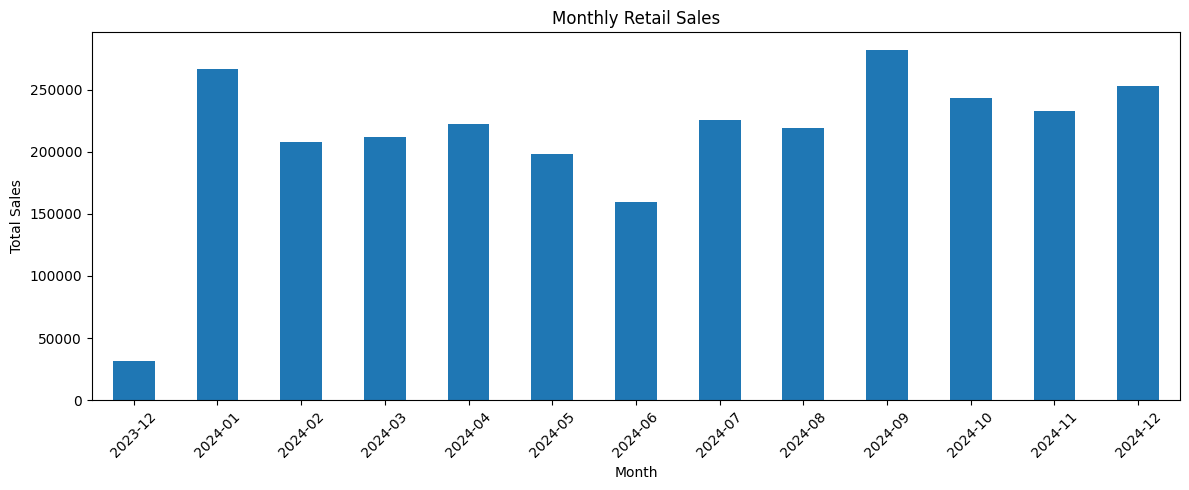

In [22]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='bar')

plt.title('Monthly Retail Sales')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [23]:
product_sales = df.groupby('Product_Name')['Total_Sales'].sum()

product_sales = product_sales.sort_values(ascending=False)

print(product_sales.head(10))

Product_Name
Headphones    162273.02
Jeans         144115.71
Eggs          140053.72
Rice          137759.99
Wall Art      129214.02
Bicycle       127962.53
Fruits        122719.40
Jacket        120671.91
Dress         120156.69
Yoga Mat      116314.63
Name: Total_Sales, dtype: float64


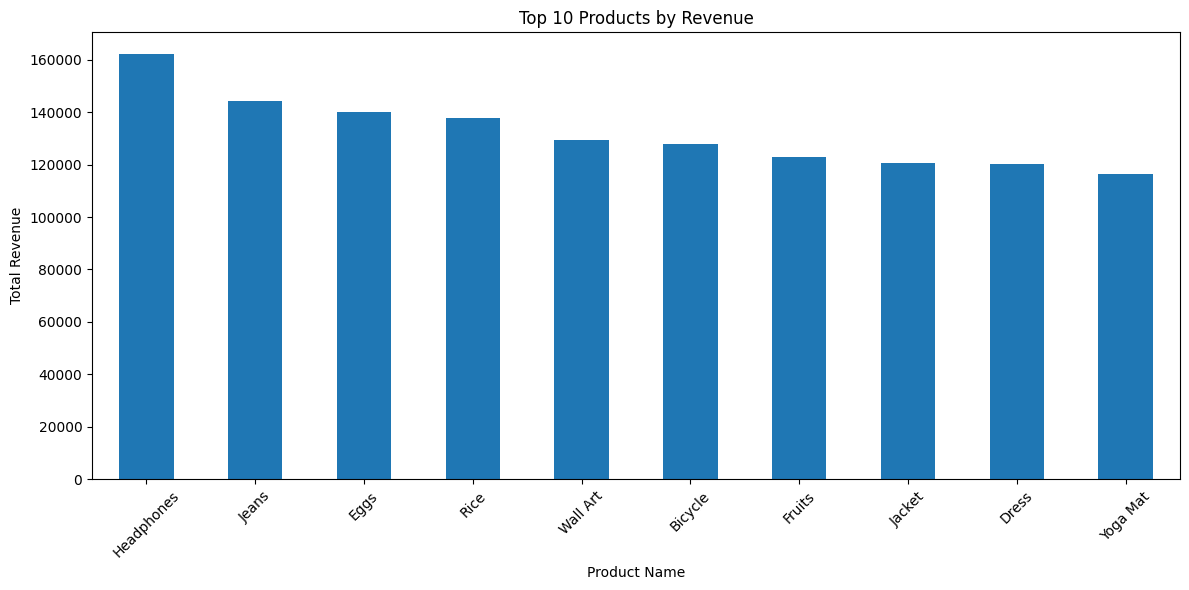

In [24]:
plt.figure(figsize=(12, 6))

product_sales.head(10).plot(kind='bar')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Product Name')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [25]:
category_sales = df.groupby('Category')['Total_Sales'].sum()

category_sales = category_sales.sort_values(ascending=False)

print(category_sales)

Category
Clothing       600020.64
Groceries      584065.33
Electronics    554400.20
Sports         538967.61
Home Decor     476812.82
Name: Total_Sales, dtype: float64


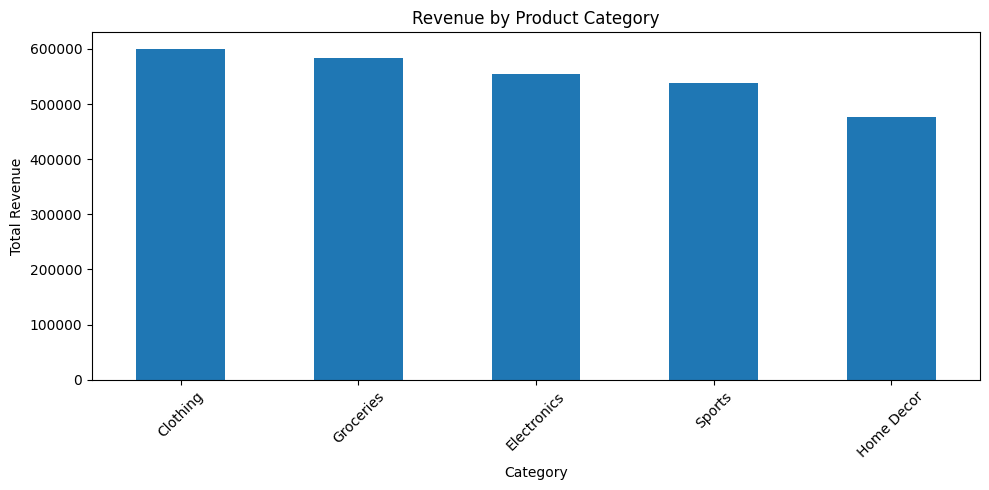

In [26]:
plt.figure(figsize=(10, 5))

category_sales.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [27]:
customer_sales = df.groupby('Customer_ID')['Total_Sales'].sum()

customer_sales = customer_sales.sort_values(ascending=False)

print(customer_sales.head(10))

Customer_ID
94    57434.76
10    50909.79
15    47194.50
95    46172.90
87    46018.68
57    44605.23
73    43139.85
41    42894.45
80    42846.51
46    42522.98
Name: Total_Sales, dtype: float64


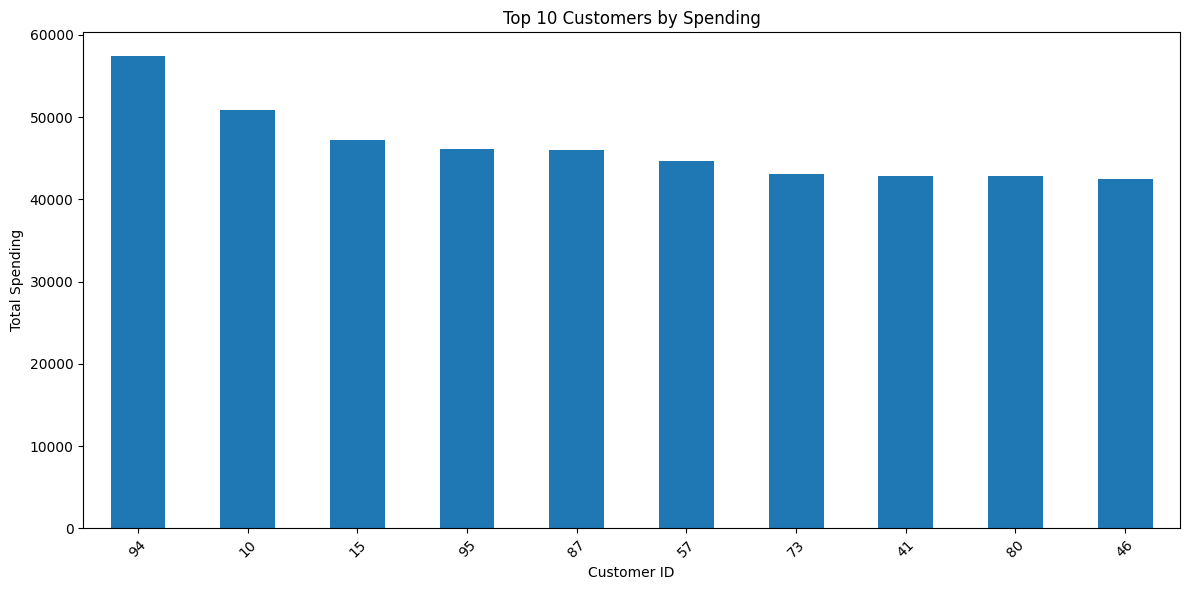

In [28]:
plt.figure(figsize=(12, 6))

customer_sales.head(10).plot(kind='bar')

plt.title('Top 10 Customers by Spending')
plt.xlabel('Customer ID')
plt.ylabel('Total Spending')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [29]:
quantity_sales = df.groupby('Product_Name')['Quantity'].sum()

quantity_sales = quantity_sales.sort_values(ascending=False)

print(quantity_sales.head(10))

Product_Name
Jeans         280
Wall Art      276
Headphones    270
Bicycle       261
Eggs          257
Rice          254
Fruits        254
Tablet        248
Jacket        244
Lamp          240
Name: Quantity, dtype: int64


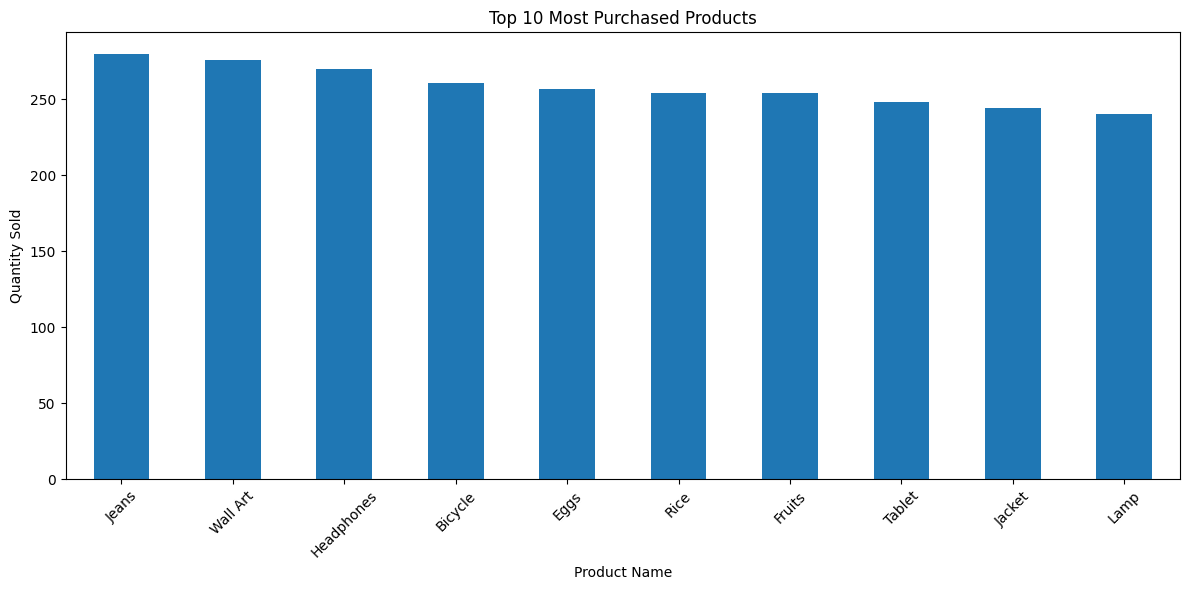

In [30]:
plt.figure(figsize=(12, 6))

quantity_sales.head(10).plot(kind='bar')

plt.title('Top 10 Most Purchased Products')
plt.xlabel('Product Name')
plt.ylabel('Quantity Sold')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [31]:
avg_category_sales = df.groupby('Category')['Total_Sales'].mean()

avg_category_sales = avg_category_sales.sort_values(ascending=False)

print(avg_category_sales)

Category
Clothing       2941.277647
Groceries      2891.412525
Electronics    2744.555446
Sports         2735.876193
Home Decor     2445.193949
Name: Total_Sales, dtype: float64


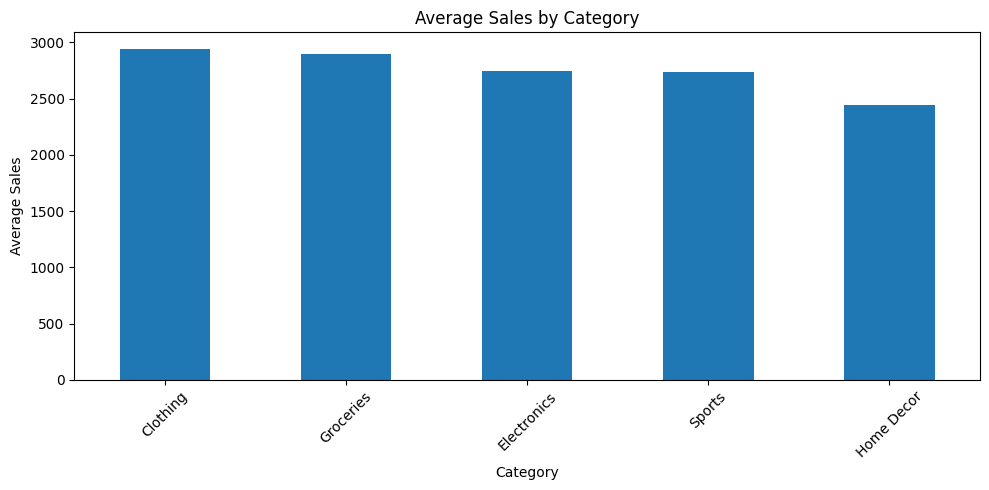

In [32]:
plt.figure(figsize=(10, 5))

avg_category_sales.plot(kind='bar')

plt.title('Average Sales by Category')
plt.xlabel('Category')
plt.ylabel('Average Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [33]:
correlation = df['Quantity'].corr(df['Total_Sales'])

print("Correlation:", correlation)

Correlation: 0.6157632887452219


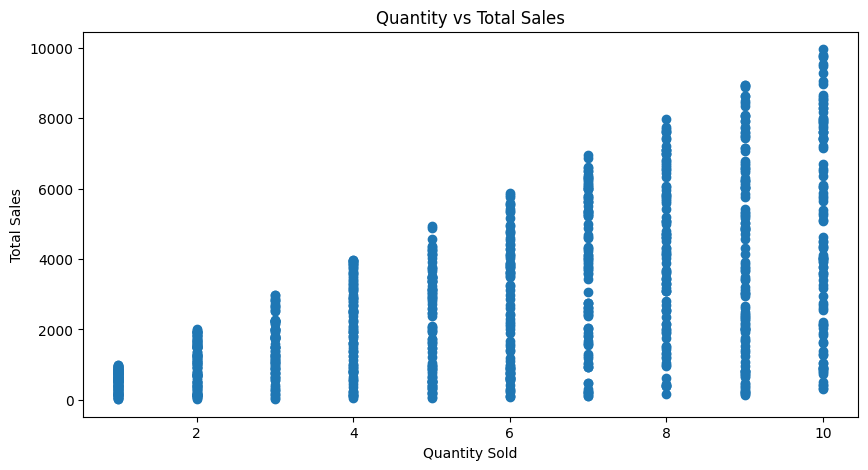

In [34]:
plt.figure(figsize=(10, 5))

plt.scatter(df['Quantity'], df['Total_Sales'])

plt.title('Quantity vs Total Sales')
plt.xlabel('Quantity Sold')
plt.ylabel('Total Sales')

plt.show()

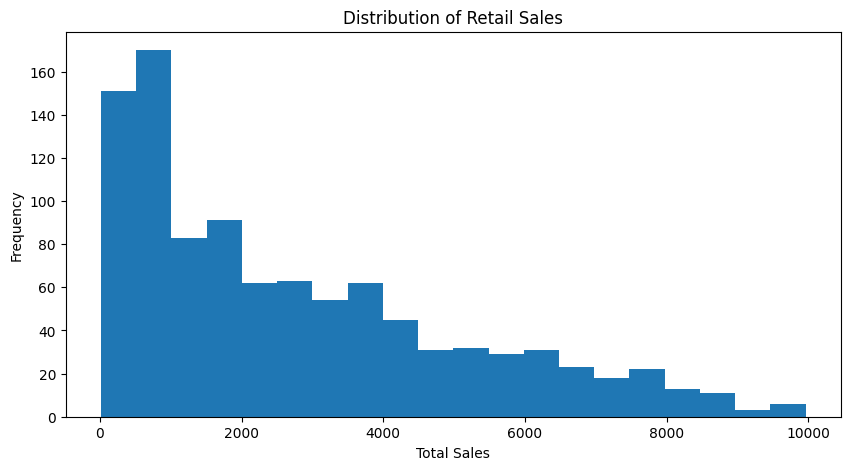

In [35]:
plt.figure(figsize=(10, 5))

plt.hist(df['Total_Sales'], bins=20)

plt.title('Distribution of Retail Sales')
plt.xlabel('Total Sales')
plt.ylabel('Frequency')

plt.show()

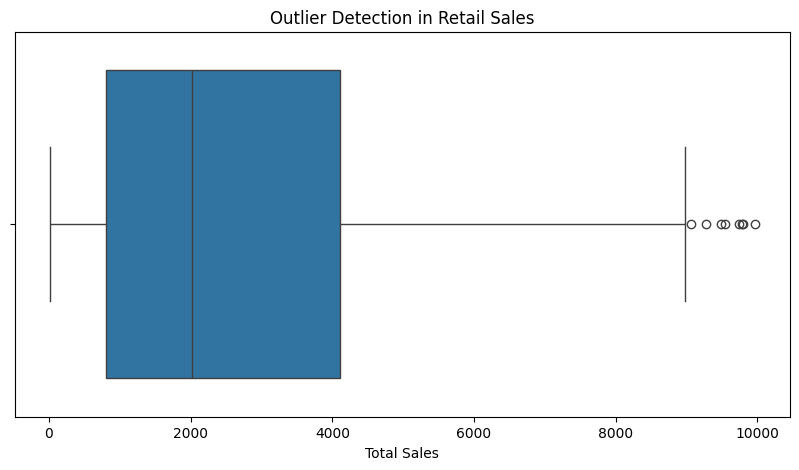

In [36]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['Total_Sales'])

plt.title('Outlier Detection in Retail Sales')
plt.xlabel('Total Sales')

plt.show()

In [37]:
Q1 = df['Total_Sales'].quantile(0.25)
Q3 = df['Total_Sales'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 806.925
Q3: 4103.174999999999
IQR: 3296.249999999999
Lower Limit: -4137.449999999998
Upper Limit: 9047.549999999997


In [38]:
outliers = df[
    (df['Total_Sales'] < lower_limit) |
    (df['Total_Sales'] > upper_limit)
]

print("Number of outliers:", len(outliers))

Number of outliers: 8


In [39]:
outliers[['Product_Name', 'Total_Sales']]

,Product_Name,Total_Sales
27,Milk,9739.3
104,Wall Art,9803.2
205,Jacket,9060.2
493,Jacket,9779.7
497,Bicycle,9536.4
644,Laptop,9277.0
841,Milk,9960.6
947,Yoga Mat,9491.3


In [40]:
outliers[['Product_Name', 'Quantity', 'Price', 'Total_Sales']]

,Product_Name,Quantity,Price,Total_Sales
27,Milk,10,973.93,9739.3
104,Wall Art,10,980.32,9803.2
205,Jacket,10,906.02,9060.2
493,Jacket,10,977.97,9779.7
497,Bicycle,10,953.64,9536.4
644,Laptop,10,927.70,9277.0
841,Milk,10,996.06,9960.6
947,Yoga Mat,10,949.13,9491.3


In [41]:
df['Is_Outlier'] = (
    (df['Total_Sales'] < lower_limit) |
    (df['Total_Sales'] > upper_limit)
)

print(df['Is_Outlier'].value_counts())

Is_Outlier
False    992
True       8
Name: count, dtype: int64


In [42]:
print("Total Revenue:", df['Total_Sales'].sum())

print("Total Units Sold:", df['Quantity'].sum())

print("Total Transactions:", df['Invoice_ID'].nunique())

print("Total Customers:", df['Customer_ID'].nunique())

print("Average Sales:", df['Total_Sales'].mean())

Total Revenue: 2754266.5999999996
Total Units Sold: 5571
Total Transactions: 1000
Total Customers: 100
Average Sales: 2754.2665999999995


In [43]:
total_revenue = df['Total_Sales'].sum()
total_units = df['Quantity'].sum()
total_transactions = df['Invoice_ID'].nunique()
total_customers = df['Customer_ID'].nunique()
average_sales = df['Total_Sales'].mean()

print("===== RETAIL SALES SUMMARY =====")
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Units Sold: {total_units:,}")
print(f"Total Transactions: {total_transactions:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Sales: {average_sales:,.2f}")

===== RETAIL SALES SUMMARY =====
Total Revenue: 2,754,266.60
Total Units Sold: 5,571
Total Transactions: 1,000
Total Customers: 100
Average Sales: 2,754.27


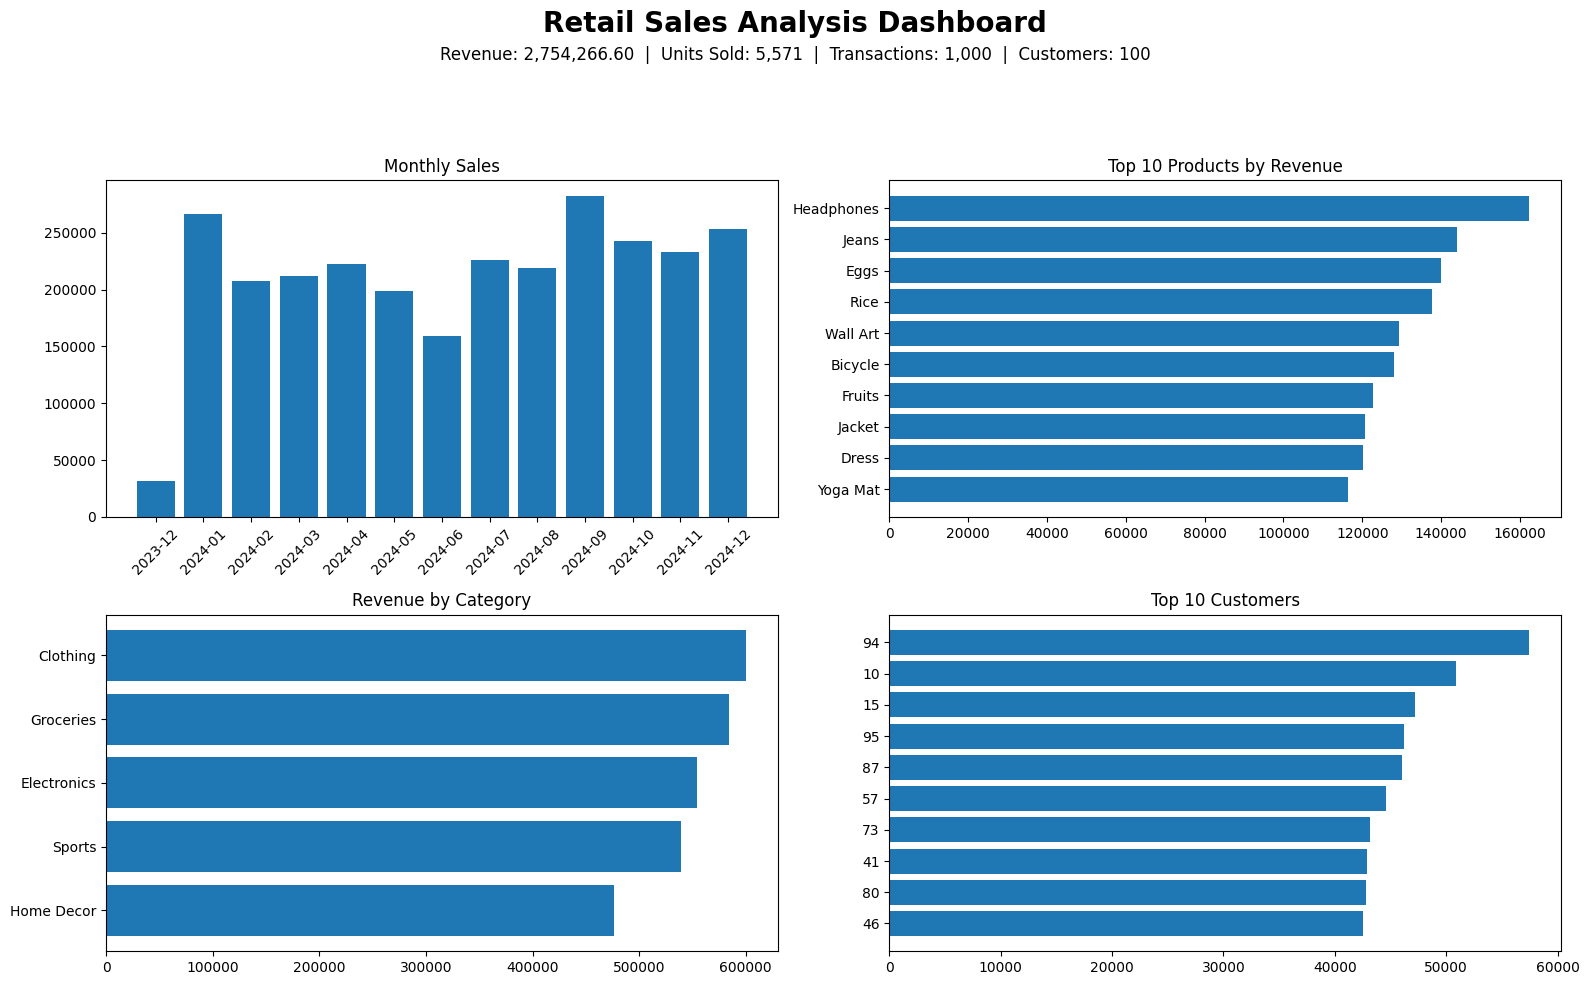

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

fig.suptitle(
    'Retail Sales Analysis Dashboard',
    fontsize=20,
    fontweight='bold'
)

fig.text(
    0.5, 0.93,
    f"Revenue: {total_revenue:,.2f}  |  "
    f"Units Sold: {total_units:,}  |  "
    f"Transactions: {total_transactions:,}  |  "
    f"Customers: {total_customers:,}",
    ha='center',
    fontsize=12
)

# 1. Monthly Sales
axes[0, 0].bar(
    monthly_sales.index.astype(str),
    monthly_sales.values
)
axes[0, 0].set_title('Monthly Sales')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Top 10 Products
top_products = product_sales.head(10).sort_values()

axes[0, 1].barh(
    top_products.index,
    top_products.values
)
axes[0, 1].set_title('Top 10 Products by Revenue')

# 3. Category Revenue
sorted_categories = category_sales.sort_values()

axes[1, 0].barh(
    sorted_categories.index,
    sorted_categories.values
)
axes[1, 0].set_title('Revenue by Category')

# 4. Top 10 Customers
top_customers = customer_sales.head(10).sort_values()

axes[1, 1].barh(
    top_customers.index.astype(str),
    top_customers.values
)
axes[1, 1].set_title('Top 10 Customers')

plt.tight_layout(rect=[0, 0, 1, 0.89])

plt.savefig(
    'Retail_Sales_Dashboard.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [45]:
df.assign(
    Year_Month=df['Year_Month'].astype(str)
).to_csv('Retail_Sales_Cleaned.csv', index=False)

In [46]:
from google.colab import files

files.download('Retail_Sales_Cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
files.download('Retail_Sales_Dashboard.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>